#### Setup

In [1]:
import shutil, subprocess, sys
from pathlib import Path

from IPython.display import SVG, display

from dvc_dat.ledger import Ledger, Ref

scratch_path = Path("scratch/q-values").resolve()
shutil.rmtree(scratch_path, ignore_errors=True)   # a re-run starts clean
for module_name in ("geometry", "plane", "plane.measure", "clips"):
    sys.modules.pop(module_name, None)
sys.path.insert(0, str(Path("demo_game").resolve()))   # the Video class

L = Ledger(scratch_path / "ledger", create=True)

# Quick: values

A value is a Python object stored in the ledger by its content: its
hash is its subject, and once stored it never changes. The quick
tour: store and name a value, find it by its preds, compute values
with ledger functions, and let the ledger remember their results.

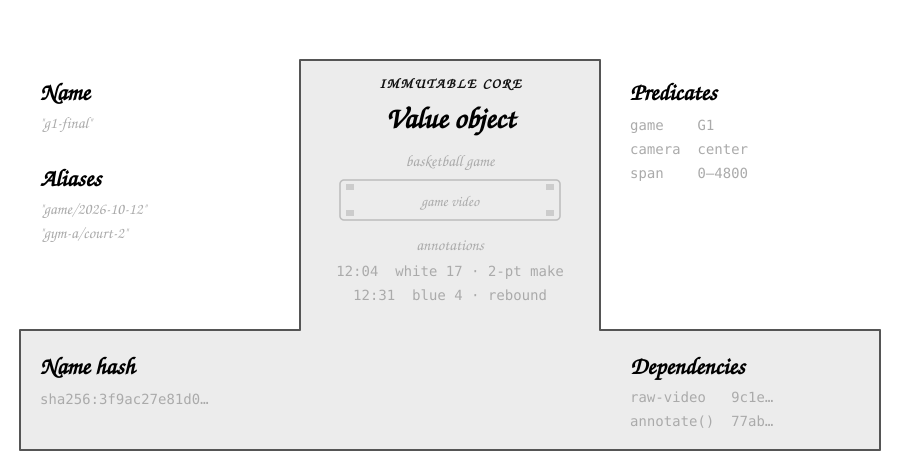

In [2]:
display(SVG(filename="q-values.svg"))   # black: the parts every value has; gray: an example

## Values

A value's class is a `Value` subclass in a module (here
`demo_game/game.py`), saying how the object becomes bytes and back,
and which preds (searchable string rows) it carries:

```python
@ledger_class(preds=("game", "camera", "span"))
class Video(Value):
    def __init__(self, frames: bytes):
        self.frames = frames
    def encode(self) -> bytes:
        return self.frames
    @classmethod
    def decode(cls, data: bytes, store) -> "Video":
        return cls(data)
```

### Storing a value, with its name

In [3]:
from demo_game.game import Video

video_value = Video(b"G1 wide camera, 9000 frames")
video_value.preds.update(game="G1", camera="wide")
with L.transaction(by="human:dan") as t:
    video_subject = video_value.seal(t, name="video/G1")
print(video_value)          # → video/G1
print(len(video_subject))   # → 64: a hash of the content

video/G1
64


`seal` stores the value and names it in one step. After the seal
the value, its preds included, is frozen.

### Referring to it: by name or by hash

In [4]:
rev1 = L.at()
by_name_video = rev1.load("video/G1")
by_hash_video = rev1.load(video_subject)
print(by_name_video.frames)                        # → b'G1 wide camera, 9000 frames'
print(by_name_video.subject == by_hash_video.subject)   # → True

b'G1 wide camera, 9000 frames'
True


## Finding values by preds

In [5]:
g2_video = Video(b"G2 wide camera, 8400 frames")
g2_video.preds.update(game="G2", camera="wide")
with L.transaction(by="human:dan") as t:
    g2_video.seal(t, name="video/G2")
rev2 = L.at()
print(rev2.values(camera="wide"))           # → [video/G1, video/G2]
print(rev2.value(game="G1", camera="wide")) # → video/G1
print(rev2.refs(kind=Video))                # → [video/G1, video/G2]

[video/G1, video/G2]
video/G1
[video/G1, video/G2]


`values` loads every match, `value` exactly one, `refs` the
matches unloaded.

## Adding an alias

A name is an alias: a `db/alias` row pointing at the value's
subject. Any number may point at one value; its name is the alias
written latest.

In [6]:
with L.transaction(by="human:dan") as t:
    t.add("raw/G1/wide-camera", "db/alias", video_subject)
camera_ref = Ref(L.at(), "raw/G1/wide-camera")
print(camera_ref.subject == video_subject)   # → True
print(sorted(camera_ref.aliases))   # → ['raw/G1/wide-camera', 'video/G1']
print(camera_ref.name)              # → raw/G1/wide-camera

True
['raw/G1/wide-camera', 'video/G1']
raw/G1/wide-camera


A `Ref` points at a value without fetching its bytes.

## Annotating a value

A value cannot change, but a row beside it can be added any time.

In [7]:
with L.transaction(by="human:dan", why="format survey") as t:
    for video_ref in L.at().refs(kind=Video):
        t.add(video_ref.subject, "resolution", "1080p")
print(Ref(L.at(), "video/G1").preds["resolution"])   # → 1080p

1080p


## Ledger functions

A ledger function is a Python function the ledger knows by dotted
name; it takes the revision first, and its result is sealed as a
value. It lives in a git repository, so the ledger can record
exactly which code ran. One is made here.

In [8]:
repo_path = scratch_path / "geometry"
repo_path.mkdir(parents=True)
git_cmd = ["git", "-c", "user.name=demo", "-c", "user.email=demo@example.com"]
(repo_path / "geometry.py").write_text('''\
import math
from dvc_dat.ledger import ledger_fn


@ledger_fn
def distance(rev, a, b=(0, 0)) -> float:
    return math.dist(a, b)
''')
for args in (["init", "-q"], ["add", "."], ["commit", "-q", "-m", "distance"]):
    subprocess.run(git_cmd + args, cwd=repo_path, check=True)
sys.path.insert(0, str(repo_path))

distance_fn = L.at().load_fn("geometry.distance")
hypotenuse_value = distance_fn(a=(3, 4))
print(hypotenuse_value.obj, hypotenuse_value.sealed)
# → 5.0 <the seal's moment>

5.0 2026-10-24T17:42:43Z


`load_fn` finds the function; calling it runs it and seals the
plain `float` it returns as a value (`.obj` unboxes it).

### Sandboxed functions

A sandboxed function runs isolated, seeing only its mounted source
folder, so its version is a checksum of the files it loaded rather
than a git commit. A mount is two rows.

In [9]:
(repo_path / "plane").mkdir()
(repo_path / "plane/measure.py").write_text('''\
import math
from dvc_dat.ledger import ledger_fn


@ledger_fn
def length(rev, a, b) -> float:
    return math.dist(a, b) * 0.5     # metres per unit
''')
for args in (["add", "."], ["commit", "-q", "-m", "plane"]):
    subprocess.run(git_cmd + args, cwd=repo_path, check=True)
with L.transaction(by="human:dan") as t:
    t.add("db/mount/plane", "db/root", "plane")
    t.add("db/mount/plane", "db/repo", "geometry")

length_fn = L.at().load_fn("plane.measure.length")
segment_value = length_fn(a=(0, 0), b=(3, 4))
print(length_fn.mode, segment_value.obj)   # → sandbox 2.5

sandbox 2.5


## Ledger evaluation

`rev.run(name, **keys)` is a lookup and a call, traced: the result
records what it depended on, and is remembered, so asking again is
answered from the ledger.

In [10]:
far_value = L.at().run("geometry.distance", a=(6, 8))
print(far_value.obj)                       # → 10.0
print(sorted(far_value.dependencies))      # → ['code/geometry', 'fn', 'platform']
top_id = L.at().id
again_value = L.at().run("geometry.distance", a=(6, 8))
print(again_value.subject == far_value.subject,
      L.at().id == top_id)                 # → True True: a hit, nothing written

10.0
['code/geometry', 'fn', 'platform']


True True


The dependencies are the code's commit, the function, and the
platform.

### A new version, and a stale result

A function that loads the video a name points at records that
binding. Seal a new version under the same name and the name
moves; the old result no longer holds, so `run` recomputes.

In [11]:
(repo_path / "clips.py").write_text('''\
from dvc_dat.ledger import ledger_fn
from demo_game.game import Video


@ledger_fn
def clip(rev, *, video: str, start: int, end: int) -> Video:
    return Video(rev.load(video).frames[start:end])
''')
for args in (["add", "."], ["commit", "-q", "-m", "clips"]):
    subprocess.run(git_cmd + args, cwd=repo_path, check=True)
opening_clip = L.at().run("clips.clip", video="video/G1", start=0, end=8)
print(opening_clip.frames)                 # → b'G1 wide '

retake_video = Video(b"G1 retake, 9100 frames")
retake_video.preds.update(game="G1", camera="wide")
with L.transaction(by="human:dan", why="the retake") as t:
    retake_video.seal(t, name="video/G1")   # the name moves
rev3 = L.at()
print(opening_clip.matches(rev3))          # → False: video/G1 moved
retake_clip = rev3.run("clips.clip", video="video/G1", start=0, end=8)
print(retake_clip.frames)                  # → b'G1 retak'
print(rev3.load(video_subject).frames)     # → b'G1 wide camera, 9000 frames'

b'G1 wide '


False


b'G1 retak'
b'G1 wide camera, 9000 frames'


A value never changes; a name moves. The old video and the old
clip stay, found by their hashes.